In [2]:
SENTIMENT_MODEL = "ProsusAI/finbert"
EMBEDDING_MODEL = "all-MiniLM-L6-v2"          
SENTIMENT_WEIGHTS = {'title': 0.6, 'content': 0.4}
#SENTIMENT_MAP = {'positive': 1.0, 'neutral': 0.0, 'negative': -1.0}
RELEVANCE_THRESHOLD = 0.25
RELEVANCE_IMPORTANCE = 1
TICKER = "AAPL"
START_DATE = "2025-11-02"
END_DATE = "2025-11-30"

In [10]:
import json
from datetime import datetime
from pathlib import Path
from typing import Any, Dict, Optional, Tuple

import torch
from sentence_transformers import SentenceTransformer, util
from transformers import AutoTokenizer, AutoModelForSequenceClassification

import warnings
warnings.filterwarnings('ignore')

_MODELS = {}

def get_device() -> str:
    return 'cuda' if torch.cuda.is_available() else 'cpu'


def load_embedding_model() -> SentenceTransformer:
    if 'embedding' not in _MODELS:
        _MODELS['embedding'] = SentenceTransformer(
            EMBEDDING_MODEL,
            device=get_device()
        )
    return _MODELS['embedding']


def load_sentiment_model() -> Tuple[AutoTokenizer, AutoModelForSequenceClassification, str]:
    if 'sentiment' not in _MODELS:
        device = get_device()
        tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL)
        model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL)
        model.to(device)
        model.eval()
        _MODELS['sentiment'] = (tokenizer, model, device)
    return _MODELS['sentiment']


def get_ticker_descriptions(ticker: str) -> list[str]:
    return [
        f"{ticker} stock price movement and performance",
        f"{ticker} earnings report and financial results",
        f"{ticker} company news and announcements",
        f"{ticker} market analysis and stock recommendations",
        f"{ticker} business operations and strategy",
        f"{ticker} product launches and innovations",
        f"news about {ticker} corporation",
        f"{ticker} quarterly results and guidance",
        f"{ticker} mergers acquisitions partnerships involving {ticker}",
        f"{ticker} executive leadership and management changes"
    ]


def compute_relevance(article_text: str, ticker: str) -> float:
    model = load_embedding_model()
    descriptions = get_ticker_descriptions(ticker)
    
    article_embedding = model.encode(article_text, convert_to_tensor=True)
    description_embeddings = model.encode(descriptions, convert_to_tensor=True)
    
    similarities = util.cos_sim(article_embedding, description_embeddings)
    return float(torch.max(similarities).cpu())


def analyze_sentiment(text: str) -> int:
    tokenizer, model, device = load_sentiment_model()
    
    inputs = tokenizer(
        text,
        return_tensors='pt',
        truncation=True,
        max_length=512,
        padding=True
    ).to(device)
    
    with torch.no_grad():
        outputs = model(**inputs)
        predictions = torch.nn.functional.softmax(outputs.logits, dim=-1)
        predicted_class = torch.argmax(predictions, dim=1).item()
    
    sentiment_mapping = {0: 1, 1: -1, 2: 0}
    return sentiment_mapping[predicted_class]


def compute_weighted_sentiment(title: str, content: str) -> float:
    title_score = analyze_sentiment(title)
    content_score = analyze_sentiment(content)
    
    return (
        SENTIMENT_WEIGHTS['title'] * title_score +
        SENTIMENT_WEIGHTS['content'] * content_score
    )


def normalize_metadata(article: Dict[str, Any]) -> Dict[str, Any]:
    normalized = article.copy()
    
    if 'title' in normalized:
        normalized['title'] = normalized['title'].strip()
    
    if 'author' in normalized and normalized['author']:
        normalized['author'] = normalized['author'].strip()
    
    if 'publishedAt' in normalized:
        try:
            dt = datetime.fromisoformat(normalized['publishedAt'].replace('Z', '+00:00'))
            normalized['publishedAt'] = dt.isoformat()
        except (ValueError, AttributeError):
            pass
    
    return normalized


def save_processed_article(
    ticker: str,
    source_filename: str,
    article: Dict[str, Any],
    final_score: float,
    relevance_score: float,
    sentiment_score: float
) -> None:
    output_dir = Path('processed') / ticker
    output_dir.mkdir(parents=True, exist_ok=True)
    
    output_data = {
        'ticker': ticker,
        'source_file': source_filename,
        'title': article.get('title', ''),
        'date': article.get('publishedAt', ''),
        'article': article,
        'relevance_score': relevance_score,
        'sentiment_score': sentiment_score,
        'final_weighted_sentiment': final_score
    }
    
    output_file = output_dir / source_filename
    with open(output_file, 'w', encoding='utf-8') as f:
        json.dump(output_data, f, indent=2)


def load_article_from_file(file_path: Path) -> Optional[Dict[str, Any]]:
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            return json.load(f)
    except Exception as e:
        print(f"    Error loading file {file_path.name}: {str(e)}")
        return None


def process_single_article(
    ticker: str, 
    article: Dict[str, Any], 
    source_filename: str
) -> Optional[Tuple[float, str, str]]:
    title = article.get('title', '').strip()
    content = article.get('content', '').strip()
    
    if not title or not content:
        print("    Skipping: missing title or content")
        return None
    
    full_text = f"{title} {content}"
    relevance_score = compute_relevance(full_text, ticker)
    
    if relevance_score < RELEVANCE_THRESHOLD:
        print(f"    Skipping: low relevance ({relevance_score:.4f} < {RELEVANCE_THRESHOLD})")
        return None
    
    sentiment_score = compute_weighted_sentiment(title, content)
    final_score = sentiment_score * (relevance_score ** RELEVANCE_IMPORTANCE)
    
    normalized_article = normalize_metadata(article)
    save_processed_article(
        ticker, 
        source_filename,
        normalized_article, 
        final_score,
        relevance_score,
        sentiment_score
    )
    
    date = normalized_article.get('publishedAt', 'N/A')
    print(f"    Processed: relevance={relevance_score:.4f}, sentiment={sentiment_score:.4f}, final={final_score:.4f}")
    
    return (final_score, title, date)


def process_articles_from_directory(ticker: str, input_dir: str) -> Dict[str, Any]:
    input_path = Path(input_dir)
    
    if not input_path.exists():
        print(f"Error: Directory '{input_dir}' does not exist")
        return {}

    json_files = sorted(input_path.glob('*.json'))
    
    if not json_files:
        print(f"Error: No JSON files found in '{input_dir}'")
        return {}
    
    print(f"\n{'='*70}")
    print(f"Processing {len(json_files)} article files for ticker: {ticker}")
    print(f"Input directory: {input_path}")
    print(f"{'='*70}\n")
    
    results = {
        'ticker': ticker,
        'input_directory': str(input_path),
        'total_files': len(json_files),
        'processed': [],
        'skipped_irrelevant': 0,
        'skipped_invalid': 0,
        'load_errors': 0,
        'average_sentiment': 0.0,
        'sentiment_distribution': {'positive': 0, 'neutral': 0, 'negative': 0}
    }
    
    for idx, json_file in enumerate(json_files, 1):
        print(f"[{idx}/{len(json_files)}] Loading: {json_file.name}")
        
        article = load_article_from_file(json_file)
        
        if article is None:
            results['load_errors'] += 1
            print()
            continue
        
        title_preview = article.get('title', 'Untitled')[:60]
        print(f"  Processing: {title_preview}...")
        
        try:
            result = process_single_article(ticker, article, json_file.name)
            
            if result is not None:
                final_score, title, date = result
                results['processed'].append({
                    'title': title,
                    'date': date,
                    'final_score': final_score,
                    'source_file': json_file.name
                })
                
                if final_score > 0.1:
                    results['sentiment_distribution']['positive'] += 1
                elif final_score < -0.1:
                    results['sentiment_distribution']['negative'] += 1
                else:
                    results['sentiment_distribution']['neutral'] += 1
            else:
                if not article.get('title', '').strip() or not article.get('content', '').strip():
                    results['skipped_invalid'] += 1
                else:
                    results['skipped_irrelevant'] += 1
                
        except Exception as e:
            print(f"  ✗ Error processing article: {str(e)}")
            results['skipped_invalid'] += 1
        
        print()
    
    if results['processed']:
        scores = [item['final_score'] for item in results['processed']]
        results['average_sentiment'] = sum(scores) / len(scores)
        results['min_sentiment'] = min(scores)
        results['max_sentiment'] = max(scores)
    
    print_summary(results)
    save_summary(ticker, results)
    
    return results


def print_summary(results: Dict[str, Any]) -> None:
    ticker = results['ticker']
    
    print(f"\n{'='*70}")
    print(f"PROCESSING SUMMARY FOR {ticker}")
    print(f"{'='*70}")
    print(f"Total files:           {results['total_files']}")
    print(f"Successfully processed: {len(results['processed'])}")
    print(f"Skipped (irrelevant):  {results['skipped_irrelevant']}")
    print(f"Skipped (invalid):     {results['skipped_invalid']}")
    print(f"Load errors:           {results['load_errors']}")
    
    if results['processed']:
        print(f"\nSentiment Statistics:")
        print(f"  Average: {results['average_sentiment']:.4f}")
        print(f"  Min:     {results['min_sentiment']:.4f}")
        print(f"  Max:     {results['max_sentiment']:.4f}")
        print(f"\nDistribution:")
        print(f"  Positive: {results['sentiment_distribution']['positive']}")
        print(f"  Neutral:  {results['sentiment_distribution']['neutral']}")
        print(f"  Negative: {results['sentiment_distribution']['negative']}")
    
    print(f"{'='*70}\n")


def save_summary(ticker: str, results: Dict[str, Any]) -> None:
    summary_dir = Path('processed') / ticker
    summary_dir.mkdir(parents=True, exist_ok=True)
    summary_file = summary_dir / 'summary.json'
    
    with open(summary_file, 'w', encoding='utf-8') as f:
        json.dump(results, f, indent=2)
    
    print(f"Summary saved to: {summary_file}\n")

In [14]:
import json
import re
from datetime import datetime
from pathlib import Path
from typing import Any, Dict, Optional, Tuple

import torch
from sentence_transformers import SentenceTransformer, util
from transformers import AutoTokenizer, AutoModelForSequenceClassification

import warnings
warnings.filterwarnings('ignore')

_MODELS = {}

def get_device() -> str:
    return 'cuda' if torch.cuda.is_available() else 'cpu'


def load_embedding_model() -> SentenceTransformer:
    if 'embedding' not in _MODELS:
        _MODELS['embedding'] = SentenceTransformer(
            EMBEDDING_MODEL,
            device=get_device()
        )
    return _MODELS['embedding']


def load_sentiment_model() -> Tuple[AutoTokenizer, AutoModelForSequenceClassification, str]:
    if 'sentiment' not in _MODELS:
        device = get_device()
        tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL)
        model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL)
        model.to(device)
        model.eval()
        _MODELS['sentiment'] = (tokenizer, model, device)
    return _MODELS['sentiment']


def get_ticker_descriptions(ticker: str) -> list[str]:
    return [
        f"{ticker} stock price movement and performance",
        f"{ticker} earnings report and financial results",
        f"{ticker} company news and announcements",
        f"{ticker} market analysis and stock recommendations",
        f"{ticker} business operations and strategy",
        f"{ticker} product launches and innovations",
        f"news about {ticker} corporation",
        f"{ticker} quarterly results and guidance",
        f"{ticker} mergers acquisitions partnerships involving {ticker}",
        f"{ticker} executive leadership and management changes",
        f"{ticker} revenue growth and profitability",
        f"{ticker} competitive position and market share",
        f"{ticker} regulatory issues and compliance",
        f"{ticker} investor sentiment and analyst ratings"
    ]


def extract_ticker_mentions(text: str, ticker: str) -> int:
    pattern = re.compile(r'\b' + re.escape(ticker) + r'\b', re.IGNORECASE)
    return len(pattern.findall(text))


def check_title_relevance(title: str, ticker: str) -> bool:
    return ticker.upper() in title.upper()


def compute_relevance_ensemble(
    article_text: str,
    title: str, 
    ticker: str,
    model: Optional[SentenceTransformer] = None
) -> dict[str, float]:
    if model is None:
        model = load_embedding_model()
    
    descriptions = get_ticker_descriptions(ticker)
    
    article_embedding = model.encode(article_text, convert_to_tensor=True)
    description_embeddings = model.encode(descriptions, convert_to_tensor=True)
    
    similarities = util.cos_sim(article_embedding, description_embeddings)
    semantic_score = float(torch.max(similarities).cpu())
    
    mention_count = extract_ticker_mentions(article_text, ticker)
    keyword_score = min(mention_count / 5.0, 1.0)
    
    title_present = check_title_relevance(title, ticker)
    title_score = 1.0 if title_present else 0.0
    
    weights = {
        'semantic': 0.6,
        'keyword': 0.25,
        'title': 0.15
    }
    
    final_score = (
        weights['semantic'] * semantic_score +
        weights['keyword'] * keyword_score +
        weights['title'] * title_score
    )
    
    return {
        'final_score': final_score,
        'semantic_score': semantic_score,
        'keyword_score': keyword_score,
        'title_score': title_score,
        'mention_count': mention_count,
        'title_present': title_present
    }


def compute_adaptive_relevance(
    article_text: str,
    title: str,
    ticker: str,
    model: Optional[SentenceTransformer] = None
) -> tuple[float, bool]:
    breakdown = compute_relevance_ensemble(article_text, title, ticker, model)
    
    final_score = breakdown['final_score']
    mention_count = breakdown['mention_count']
    title_present = breakdown['title_present']
    
    if title_present and mention_count >= 2:
        is_relevant = final_score >= 0.3
    elif title_present or mention_count >= 3:
        is_relevant = final_score >= 0.4
    else:
        is_relevant = final_score >= RELEVANCE_THRESHOLD
    
    return final_score, is_relevant


def analyze_sentiment(text: str) -> int:
    tokenizer, model, device = load_sentiment_model()
    
    inputs = tokenizer(
        text,
        return_tensors='pt',
        truncation=True,
        max_length=512,
        padding=True
    ).to(device)
    
    with torch.no_grad():
        outputs = model(**inputs)
        predictions = torch.nn.functional.softmax(outputs.logits, dim=-1)
        predicted_class = torch.argmax(predictions, dim=1).item()
    
    sentiment_mapping = {0: 1, 1: -1, 2: 0}
    return sentiment_mapping[predicted_class]


def compute_weighted_sentiment(title: str, content: str) -> float:
    title_score = analyze_sentiment(title)
    content_score = analyze_sentiment(content)
    
    return (
        SENTIMENT_WEIGHTS['title'] * title_score +
        SENTIMENT_WEIGHTS['content'] * content_score
    )


def normalize_metadata(article: Dict[str, Any]) -> Dict[str, Any]:
    normalized = article.copy()
    
    if 'title' in normalized:
        normalized['title'] = normalized['title'].strip()
    
    if 'author' in normalized and normalized['author']:
        normalized['author'] = normalized['author'].strip()
    
    if 'publishedAt' in normalized:
        try:
            dt = datetime.fromisoformat(normalized['publishedAt'].replace('Z', '+00:00'))
            normalized['publishedAt'] = dt.isoformat()
        except (ValueError, AttributeError):
            pass
    
    return normalized


def save_processed_article(
    ticker: str,
    source_filename: str,
    article: Dict[str, Any],
    final_score: float,
    relevance_score: float,
    sentiment_score: float
) -> None:
    output_dir = Path('processed') / ticker
    output_dir.mkdir(parents=True, exist_ok=True)
    
    output_data = {
        'ticker': ticker,
        'source_file': source_filename,
        'title': article.get('title', ''),
        'date': article.get('publishedAt', ''),
        'article': article,
        'relevance_score': relevance_score,
        'sentiment_score': sentiment_score,
        'final_weighted_sentiment': final_score
    }
    
    output_file = output_dir / source_filename
    with open(output_file, 'w', encoding='utf-8') as f:
        json.dump(output_data, f, indent=2)


def load_article_from_file(file_path: Path) -> Optional[Dict[str, Any]]:
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            return json.load(f)
    except Exception as e:
        print(f"    Error loading file {file_path.name}: {str(e)}")
        return None


def process_single_article(
    ticker: str, 
    article: Dict[str, Any], 
    source_filename: str,
    use_adaptive: bool = True,
    verbose: bool = False
) -> Optional[Tuple[float, str, str]]:
    title = article.get('title', '').strip()
    content = article.get('content', '').strip()
    
    if not title or not content:
        print("    Skipping: missing title or content")
        return None
    
    full_text = f"{title} {content}"
    model = load_embedding_model()
    
    if use_adaptive:
        relevance_score, is_relevant = compute_adaptive_relevance(
            full_text, title, ticker, model
        )
        
        if not is_relevant:
            print(f"    Skipping: low relevance ({relevance_score:.4f})")
            return None
    else:
        relevance_breakdown = compute_relevance_ensemble(
            full_text, title, ticker, model
        )
        relevance_score = relevance_breakdown['final_score']
        
        if relevance_score < RELEVANCE_THRESHOLD:
            print(f"    Skipping: low relevance ({relevance_score:.4f} < {RELEVANCE_THRESHOLD})")
            if verbose:
                print(f"      Breakdown: semantic={relevance_breakdown['semantic_score']:.3f}, "
                      f"keyword={relevance_breakdown['keyword_score']:.3f}, "
                      f"title={relevance_breakdown['title_score']:.3f}")
            return None
    
    sentiment_score = compute_weighted_sentiment(title, content)
    final_score = sentiment_score * (relevance_score ** RELEVANCE_IMPORTANCE)
    
    normalized_article = normalize_metadata(article)
    save_processed_article(
        ticker, 
        source_filename,
        normalized_article, 
        final_score,
        relevance_score,
        sentiment_score
    )
    
    date = normalized_article.get('publishedAt', 'N/A')
    print(f"    Processed: relevance={relevance_score:.4f}, sentiment={sentiment_score:.4f}, final={final_score:.4f}")
    
    return (final_score, title, date)


def process_articles_from_directory(
    ticker: str, 
    input_dir: str,
    use_adaptive: bool = True,
    verbose: bool = False
) -> Dict[str, Any]:
    input_path = Path(input_dir)
    
    if not input_path.exists():
        print(f"Error: Directory '{input_dir}' does not exist")
        return {}

    json_files = sorted(input_path.glob('*.json'))
    
    if not json_files:
        print(f"Error: No JSON files found in '{input_dir}'")
        return {}
    
    print(f"\n{'='*70}")
    print(f"Processing {len(json_files)} article files for ticker: {ticker}")
    print(f"Input directory: {input_path}")
    print(f"Relevance mode: {'Adaptive' if use_adaptive else 'Standard'}")
    print(f"{'='*70}\n")
    
    results = {
        'ticker': ticker,
        'input_directory': str(input_path),
        'total_files': len(json_files),
        'processed': [],
        'skipped_irrelevant': 0,
        'skipped_invalid': 0,
        'load_errors': 0,
        'average_sentiment': 0.0,
        'sentiment_distribution': {'positive': 0, 'neutral': 0, 'negative': 0}
    }
    
    for idx, json_file in enumerate(json_files, 1):
        print(f"[{idx}/{len(json_files)}] Loading: {json_file.name}")
        
        article = load_article_from_file(json_file)
        
        if article is None:
            results['load_errors'] += 1
            print()
            continue
        
        title_preview = article.get('title', 'Untitled')[:60]
        print(f"  Processing: {title_preview}...")
        
        try:
            result = process_single_article(ticker, article, json_file.name, use_adaptive, verbose)
            
            if result is not None:
                final_score, title, date = result
                results['processed'].append({
                    'title': title,
                    'date': date,
                    'final_score': final_score,
                    'source_file': json_file.name
                })
                
                if final_score > 0.1:
                    results['sentiment_distribution']['positive'] += 1
                elif final_score < -0.1:
                    results['sentiment_distribution']['negative'] += 1
                else:
                    results['sentiment_distribution']['neutral'] += 1
            else:
                if not article.get('title', '').strip() or not article.get('content', '').strip():
                    results['skipped_invalid'] += 1
                else:
                    results['skipped_irrelevant'] += 1
                
        except Exception as e:
            print(f"  ✗ Error processing article: {str(e)}")
            results['skipped_invalid'] += 1
        
        print()
    
    if results['processed']:
        scores = [item['final_score'] for item in results['processed']]
        results['average_sentiment'] = sum(scores) / len(scores)
        results['min_sentiment'] = min(scores)
        results['max_sentiment'] = max(scores)
    
    print_summary(results)
    save_summary(ticker, results)
    
    return results


def print_summary(results: Dict[str, Any]) -> None:
    ticker = results['ticker']
    
    print(f"\n{'='*70}")
    print(f"PROCESSING SUMMARY FOR {ticker}")
    print(f"{'='*70}")
    print(f"Total files:           {results['total_files']}")
    print(f"Successfully processed: {len(results['processed'])}")
    print(f"Skipped (irrelevant):  {results['skipped_irrelevant']}")
    print(f"Skipped (invalid):     {results['skipped_invalid']}")
    print(f"Load errors:           {results['load_errors']}")
    
    if results['processed']:
        print(f"\nSentiment Statistics:")
        print(f"  Average: {results['average_sentiment']:.4f}")
        print(f"  Min:     {results['min_sentiment']:.4f}")
        print(f"  Max:     {results['max_sentiment']:.4f}")
        print(f"\nDistribution:")
        print(f"  Positive: {results['sentiment_distribution']['positive']}")
        print(f"  Neutral:  {results['sentiment_distribution']['neutral']}")
        print(f"  Negative: {results['sentiment_distribution']['negative']}")
    
    print(f"{'='*70}\n")


def save_summary(ticker: str, results: Dict[str, Any]) -> None:
    summary_dir = Path('processed') / ticker
    summary_dir.mkdir(parents=True, exist_ok=True)
    summary_file = summary_dir / 'summary.json'
    
    with open(summary_file, 'w', encoding='utf-8') as f:
        json.dump(results, f, indent=2)
    
    print(f"Summary saved to: {summary_file}\n")

In [16]:
input_directory = r"D:\Vedant's Stuff\Finance\Decay_Someday\newsapiArticlesRedditComparision"
    
results = process_articles_from_directory(TICKER, input_directory)
    
if results.get('processed'):
    print("\nTop 10 Processed Articles by Sentiment:")
    print("-" * 70)
    sorted_articles = sorted(
        results['processed'], 
        key=lambda x: x['final_score'], 
            reverse=True
        )[:10]
        
    for item in sorted_articles:
        print(f"Title: {item['title'][:60]}")
        print(f"Date:  {item['date']}")
        print(f"Score: {item['final_score']:.4f}")
        print(f"File:  {item['source_file']}")
        print("-" * 70)


Processing 2641 article files for ticker: AAPL
Input directory: D:\Vedant's Stuff\Finance\Decay_Someday\newsapiArticlesRedditComparision
Relevance mode: Adaptive

[1/2641] Loading: NewsAPI_2025-11-02_0.json
  Processing: [iOS] LiDAR 3D Floor Plan Creator - Free in-App Lifetime Sub...
    Skipping: low relevance (0.1166)

[2/2641] Loading: NewsAPI_2025-11-02_1.json
  Processing: Apple Gears Up For A Pivotal Year With Major Product Release...
    Processed: relevance=0.3591, sentiment=1.0000, final=0.3591

[3/2641] Loading: NewsAPI_2025-11-02_10.json
  Processing: BJ's Wholesale Club: Apple iPad 11" A16 128GB WiFi for $279....
    Skipping: low relevance (0.2141)

[4/2641] Loading: NewsAPI_2025-11-02_11.json
  Processing: Top 10 trending phones of week 44...
    Skipping: low relevance (0.2383)

[5/2641] Loading: NewsAPI_2025-11-02_13.json
  Processing: Beauty and the Backbone: Why Apple and Microsoft Are Both Ri...
    Skipping: low relevance (0.1976)

[6/2641] Loading: NewsAPI_2025-11

In [19]:
import json
from pathlib import Path
from datetime import datetime, timedelta
from collections import defaultdict
from typing import Dict, List, Tuple, Optional

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import yfinance as yf
from scipy.ndimage import gaussian_filter1d


def load_processed_articles(
    ticker: str, 
    processed_dir: str = "processed",
    relevance_threshold: float = RELEVANCE_THRESHOLD
) -> Tuple[Dict, int, int]:
    ticker_dir = Path(processed_dir) / ticker
    
    if not ticker_dir.exists():
        raise FileNotFoundError(f"Directory '{ticker_dir}' does not exist")
    
    json_files = [f for f in ticker_dir.glob('*.json') if f.name != 'summary.json']
    
    if not json_files:
        raise FileNotFoundError(f"No processed articles found in '{ticker_dir}'")
    
    print(f"Loading {len(json_files)} processed articles for {ticker}...")
    
    daily_sentiments = defaultdict(list)
    processed_count = 0
    filtered_count = 0
    
    for json_file in json_files:
        try:
            with open(json_file, 'r', encoding='utf-8') as f:
                data = json.load(f)
            
            relevance = data.get('relevance_score', 0)
            if relevance <= relevance_threshold:
                filtered_count += 1
                continue
            
            date_str = data.get('date', '')
            sentiment = data.get('final_weighted_sentiment', 0)
            
            if date_str:
                try:
                    dt = datetime.fromisoformat(date_str.replace('Z', '+00:00'))
                    date_key = dt.date()
                    daily_sentiments[date_key].append(sentiment)
                    processed_count += 1
                except Exception:
                    print(f"  Warning: Could not parse date '{date_str}' in {json_file.name}")
        
        except Exception as e:
            print(f"  Error loading {json_file.name}: {str(e)}")
    
    print(f"Processed: {processed_count} articles")
    print(f"Filtered out: {filtered_count} articles (below threshold)")
    
    return daily_sentiments, processed_count, filtered_count


def fetch_price_data(ticker: str, start_date: str, end_date: str) -> Tuple[np.ndarray, np.ndarray]:
    ticker_obj = yf.Ticker(ticker)
    df = ticker_obj.history(start=start_date, end=end_date)
    
    if df.empty:
        raise ValueError(f"No price data found for {ticker} between {start_date} and {end_date}")
    
    return df.index.to_pydatetime(), df["Close"].values


def compute_sentiment_statistics(daily_sentiments: Dict) -> Dict:
    dates = sorted(daily_sentiments.keys())
    
    stats = {
        'dates': dates,
        'avg_sentiments': [np.mean(daily_sentiments[d]) for d in dates],
        'article_counts': [len(daily_sentiments[d]) for d in dates],
        'pos_daily': [],
        'neg_daily': [],
        'std_daily': [],
        'median_daily': []
    }
    
    for day in dates:
        scores = daily_sentiments[day]
        
        pos_vals = [v for v in scores if v > 0.1]
        neg_vals = [v for v in scores if v < -0.1]
        
        stats['pos_daily'].append(np.mean(pos_vals) if pos_vals else None)
        stats['neg_daily'].append(np.mean(neg_vals) if neg_vals else None)
        stats['std_daily'].append(np.std(scores))
        stats['median_daily'].append(np.median(scores))
    
    return stats


def compute_moving_average(values: List[float], window: int = 3) -> List[float]:
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window)/window, mode='valid').tolist()


def compute_cumulative_sentiment(sentiments: List[float]) -> List[float]:
    return np.cumsum(sentiments).tolist()


def normalize_prices(prices: np.ndarray) -> np.ndarray:
    return (prices - prices[0]) / prices[0] * 100


def plot_daily_sentiment(
    ticker: str,
    processed_dir: str = "processed",
    relevance_threshold: float = RELEVANCE_THRESHOLD,
    show_moving_avg: bool = True,
    ma_window: int = 3,
    normalize_price: bool = True,
    figsize: Tuple[int, int] = (20, 32)
):
    try:
        daily_sentiments, processed_count, filtered_count = load_processed_articles(
            ticker, processed_dir, relevance_threshold
        )
    except (FileNotFoundError, ValueError) as e:
        print(f"Error: {e}")
        return
    
    if not daily_sentiments:
        print(f"No articles passed the relevance threshold of {relevance_threshold}")
        return
    
    try:
        price_dates, close_prices = fetch_price_data(ticker, START_DATE, END_DATE)
    except ValueError as e:
        print(f"Error: {e}")
        return
    
    stats = compute_sentiment_statistics(daily_sentiments)
    dates = stats['dates']
    avg_sentiments = stats['avg_sentiments']
    
    fig, axes = plt.subplots(6, 1, figsize=figsize, sharex=False)
    fig.suptitle(f'Sentiment Analysis Dashboard for {ticker}', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    # Plot 1: Average Daily Sentiment with Moving Average
    ax1 = axes[0]
    ax1.plot(dates, avg_sentiments, marker='o', linewidth=2, markersize=5, 
             color='#2E86AB', label='Daily Average', alpha=0.7)
    
    if show_moving_avg and len(avg_sentiments) >= ma_window:
        ma_dates = dates[ma_window-1:]
        ma_values = compute_moving_average(avg_sentiments, ma_window)
        ax1.plot(ma_dates, ma_values, linewidth=3, color='#E63946', 
                label=f'{ma_window}-Day MA', alpha=0.9)
    
    ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
    ax1.fill_between(dates, avg_sentiments, 0, alpha=0.2, color='#2E86AB')
    
    ax1.set_ylabel('Average Sentiment', fontsize=11, fontweight='bold')
    ax1.set_title(f'Daily Average Sentiment (Relevance ≥ {relevance_threshold})',
                  fontsize=13, fontweight='bold', pad=15)
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.legend(loc='best', fontsize=10)
    
    y_range = max(avg_sentiments) - min(avg_sentiments)
    ax1.set_ylim(min(avg_sentiments) - 0.15*y_range, max(avg_sentiments) + 0.15*y_range)
    
    # Plot 2: Positive vs Negative Sentiment
    ax2 = axes[1]
    
    pos_dates = [d for d, v in zip(dates, stats['pos_daily']) if v is not None]
    pos_vals = [v for v in stats['pos_daily'] if v is not None]
    neg_dates = [d for d, v in zip(dates, stats['neg_daily']) if v is not None]
    neg_vals = [v for v in stats['neg_daily'] if v is not None]
    
    if pos_vals:
        ax2.plot(pos_dates, pos_vals, marker='o', linewidth=2, markersize=5,
                label='Positive', color='#2ECC71', alpha=0.8)
    if neg_vals:
        ax2.plot(neg_dates, neg_vals, marker='o', linewidth=2, markersize=5,
                label='Negative', color='#E74C3C', alpha=0.8)
    
    ax2.axhline(y=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
    ax2.set_ylabel('Sentiment Score', fontsize=11, fontweight='bold')
    ax2.set_title('Positive vs Negative Sentiment Trends', 
                  fontsize=13, fontweight='bold', pad=15)
    ax2.grid(True, alpha=0.3, linestyle='--')
    ax2.legend(loc='best', fontsize=10)
    
    # Plot 3: Price Chart
    ax3 = axes[2]
    
    if normalize_price:
        normalized_prices = normalize_prices(close_prices)
        ax3.plot(price_dates, normalized_prices, linewidth=2.5, color='#2E86AB', alpha=0.8)
        ax3.fill_between(price_dates, normalized_prices, 0, alpha=0.2, color='#2E86AB')
        ax3.set_ylabel('Price Change (%)', fontsize=11, fontweight='bold')
        ax3.axhline(y=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
    else:
        ax3.plot(price_dates, close_prices, linewidth=2.5, color='#2E86AB', alpha=0.8)
        ax3.fill_between(price_dates, close_prices, min(close_prices), 
                        alpha=0.2, color='#2E86AB')
        ax3.set_ylabel('Closing Price ($)', fontsize=11, fontweight='bold')
    
    ax3.set_title(f'Price History ({START_DATE} → {END_DATE})',
                  fontsize=13, fontweight='bold', pad=15)
    ax3.grid(True, alpha=0.3, linestyle='--')
    
    # Plot 4: Individual Sentiment Distribution
    ax4 = axes[3]
    
    all_dates = []
    all_scores = []
    colors = []
    
    for date, scores in daily_sentiments.items():
        for s in scores:
            all_dates.append(date)
            all_scores.append(s)
            if s > 0.1:
                colors.append('#2ECC71')
            elif s < -0.1:
                colors.append('#E74C3C')
            else:
                colors.append('#95A5A6')
    
    ax4.scatter(all_dates, all_scores, s=50, alpha=0.6, c=colors, edgecolors='black', linewidth=0.5)
    ax4.axhline(y=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
    ax4.set_ylabel('Sentiment Score', fontsize=11, fontweight='bold')
    ax4.set_title('Individual Article Sentiment Distribution',
                  fontsize=13, fontweight='bold', pad=15)
    ax4.grid(True, alpha=0.3, linestyle='--')
    
    # Plot 5: Cumulative Sentiment
    ax5 = axes[4]
    
    cumulative = compute_cumulative_sentiment(avg_sentiments)
    ax5.plot(dates, cumulative, linewidth=3, color='#9B59B6', alpha=0.8)
    ax5.fill_between(dates, cumulative, 0, alpha=0.2, color='#9B59B6')
    ax5.axhline(y=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
    ax5.set_ylabel('Cumulative Sentiment', fontsize=11, fontweight='bold')
    ax5.set_title('Cumulative Sentiment Trend',
                  fontsize=13, fontweight='bold', pad=15)
    ax5.grid(True, alpha=0.3, linestyle='--')
    
    # Plot 6: Article Volume
    ax6 = axes[5]
    
    colors_volume = ['#2ECC71' if s > 0 else '#E74C3C' if s < 0 else '#95A5A6' 
                     for s in avg_sentiments]
    ax6.bar(dates, stats['article_counts'], color=colors_volume, 
            alpha=0.7, edgecolor='black', linewidth=0.5)
    ax6.set_xlabel('Date', fontsize=11, fontweight='bold')
    ax6.set_ylabel('Article Count', fontsize=11, fontweight='bold')
    ax6.set_title('Daily Article Volume (colored by sentiment)',
                  fontsize=13, fontweight='bold', pad=15)
    ax6.grid(True, alpha=0.3, linestyle='--', axis='y')
    
    for ax in axes:
        ax.tick_params(axis='x', rotation=45)
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    
    plt.tight_layout()
    
    output_dir = Path('plots')
    output_dir.mkdir(exist_ok=True)
    output_file = output_dir / f'{ticker}_sentiment_analysis.png'
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    print(f"\nPlot saved to: {output_file}")
    
    plt.show()


def plot_sentiment_vs_price(
    ticker: str,
    processed_dir: str = "processed",
    relevance_threshold: float = RELEVANCE_THRESHOLD,
    lag_days: int = 0
):
    try:
        daily_sentiments, _, _ = load_processed_articles(
            ticker, processed_dir, relevance_threshold
        )
        price_dates, close_prices = fetch_price_data(ticker, START_DATE, END_DATE)
    except (FileNotFoundError, ValueError) as e:
        print(f"Error: {e}")
        return
    
    if not daily_sentiments:
        return
    
    stats = compute_sentiment_statistics(daily_sentiments)
    dates = stats['dates']
    avg_sentiments = stats['avg_sentiments']
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(20, 12), sharex=True)
    fig.suptitle(f'Sentiment vs Price Analysis for {ticker}', 
                 fontsize=16, fontweight='bold')
    
    # Sentiment plot
    ax1.plot(dates, avg_sentiments, marker='o', linewidth=2, color='#E63946', 
             label='Average Sentiment')
    ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
    ax1.fill_between(dates, avg_sentiments, 0, alpha=0.3, color='#E63946')
    ax1.set_ylabel('Sentiment Score', fontsize=12, fontweight='bold')
    ax1.set_title('Daily Sentiment', fontsize=13, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Price plot
    normalized_prices = normalize_prices(close_prices)
    ax2.plot(price_dates, normalized_prices, linewidth=2, color='#2E86AB',
             label='Price Change (%)')
    ax2.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
    ax2.fill_between(price_dates, normalized_prices, 0, alpha=0.3, color='#2E86AB')
    ax2.set_ylabel('Price Change (%)', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=12, fontweight='bold')
    ax2.set_title('Normalized Price Movement', fontsize=13, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

Loading 68 processed articles for AAPL...
Processed: 68 articles
Filtered out: 0 articles (below threshold)

Plot saved to: plots\AAPL_sentiment_analysis.png


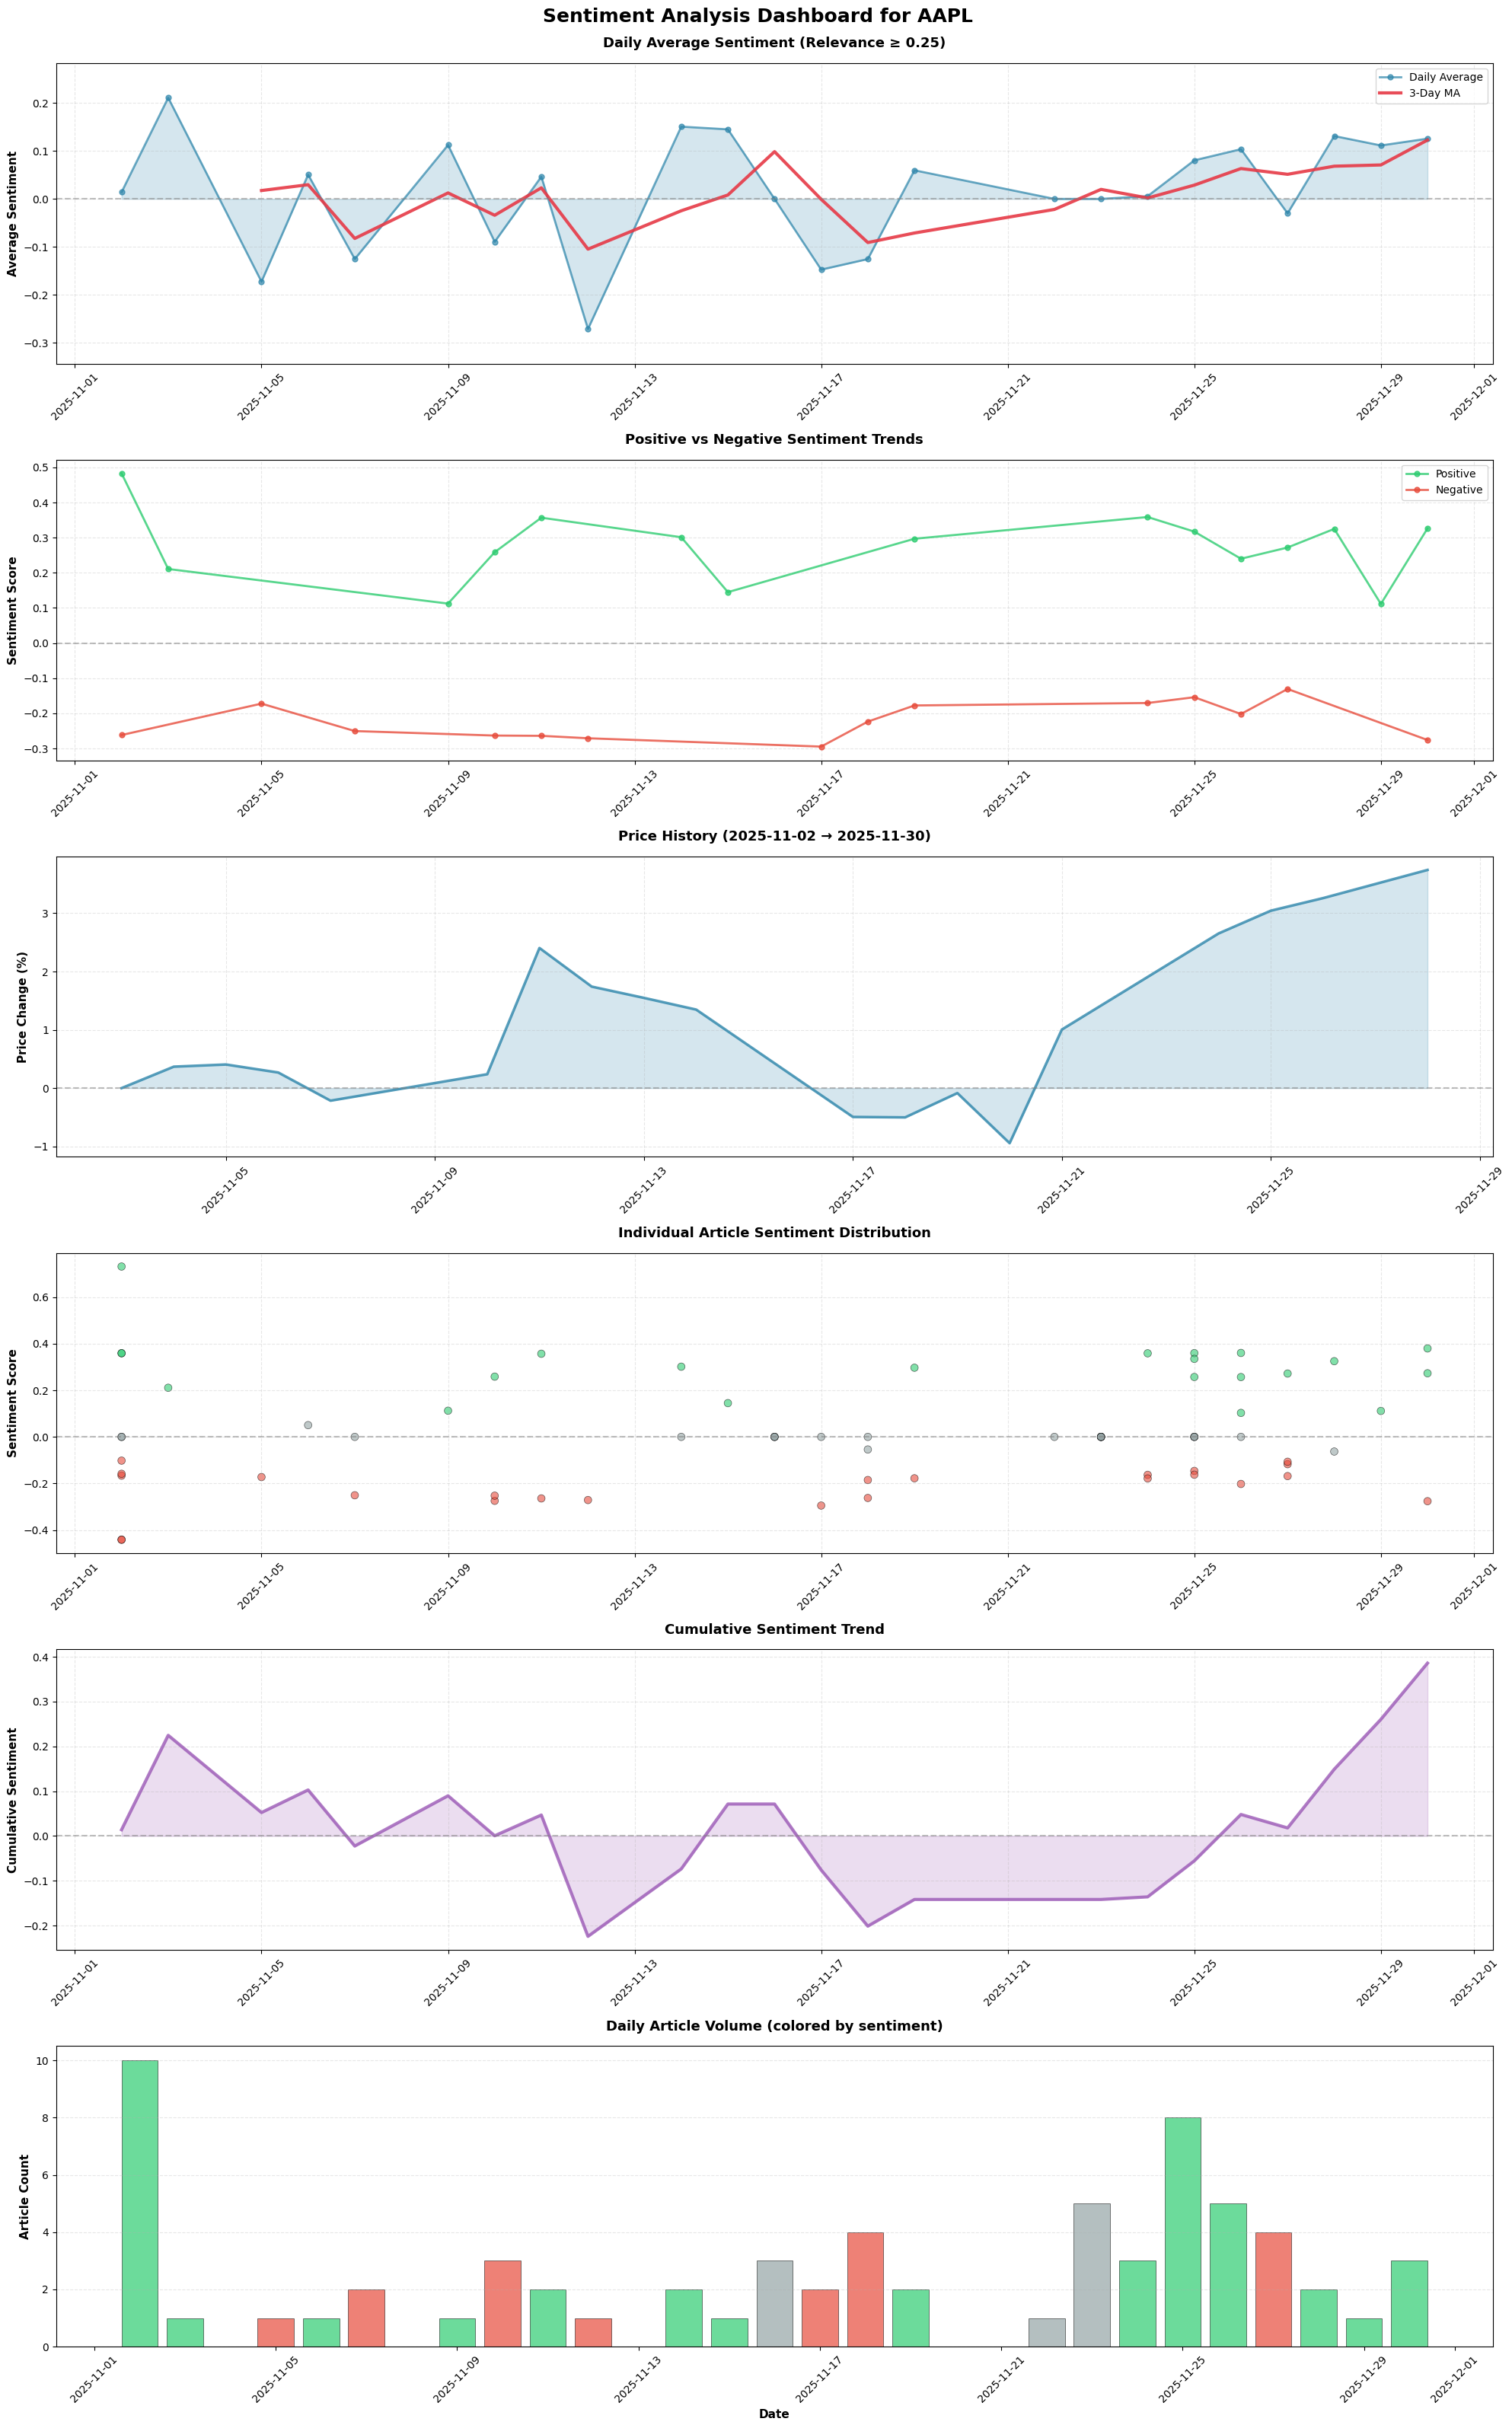

In [20]:
plot_daily_sentiment(TICKER)

Loading 68 processed articles for AAPL...
Processed: 68 articles
Filtered out: 0 articles (below threshold)


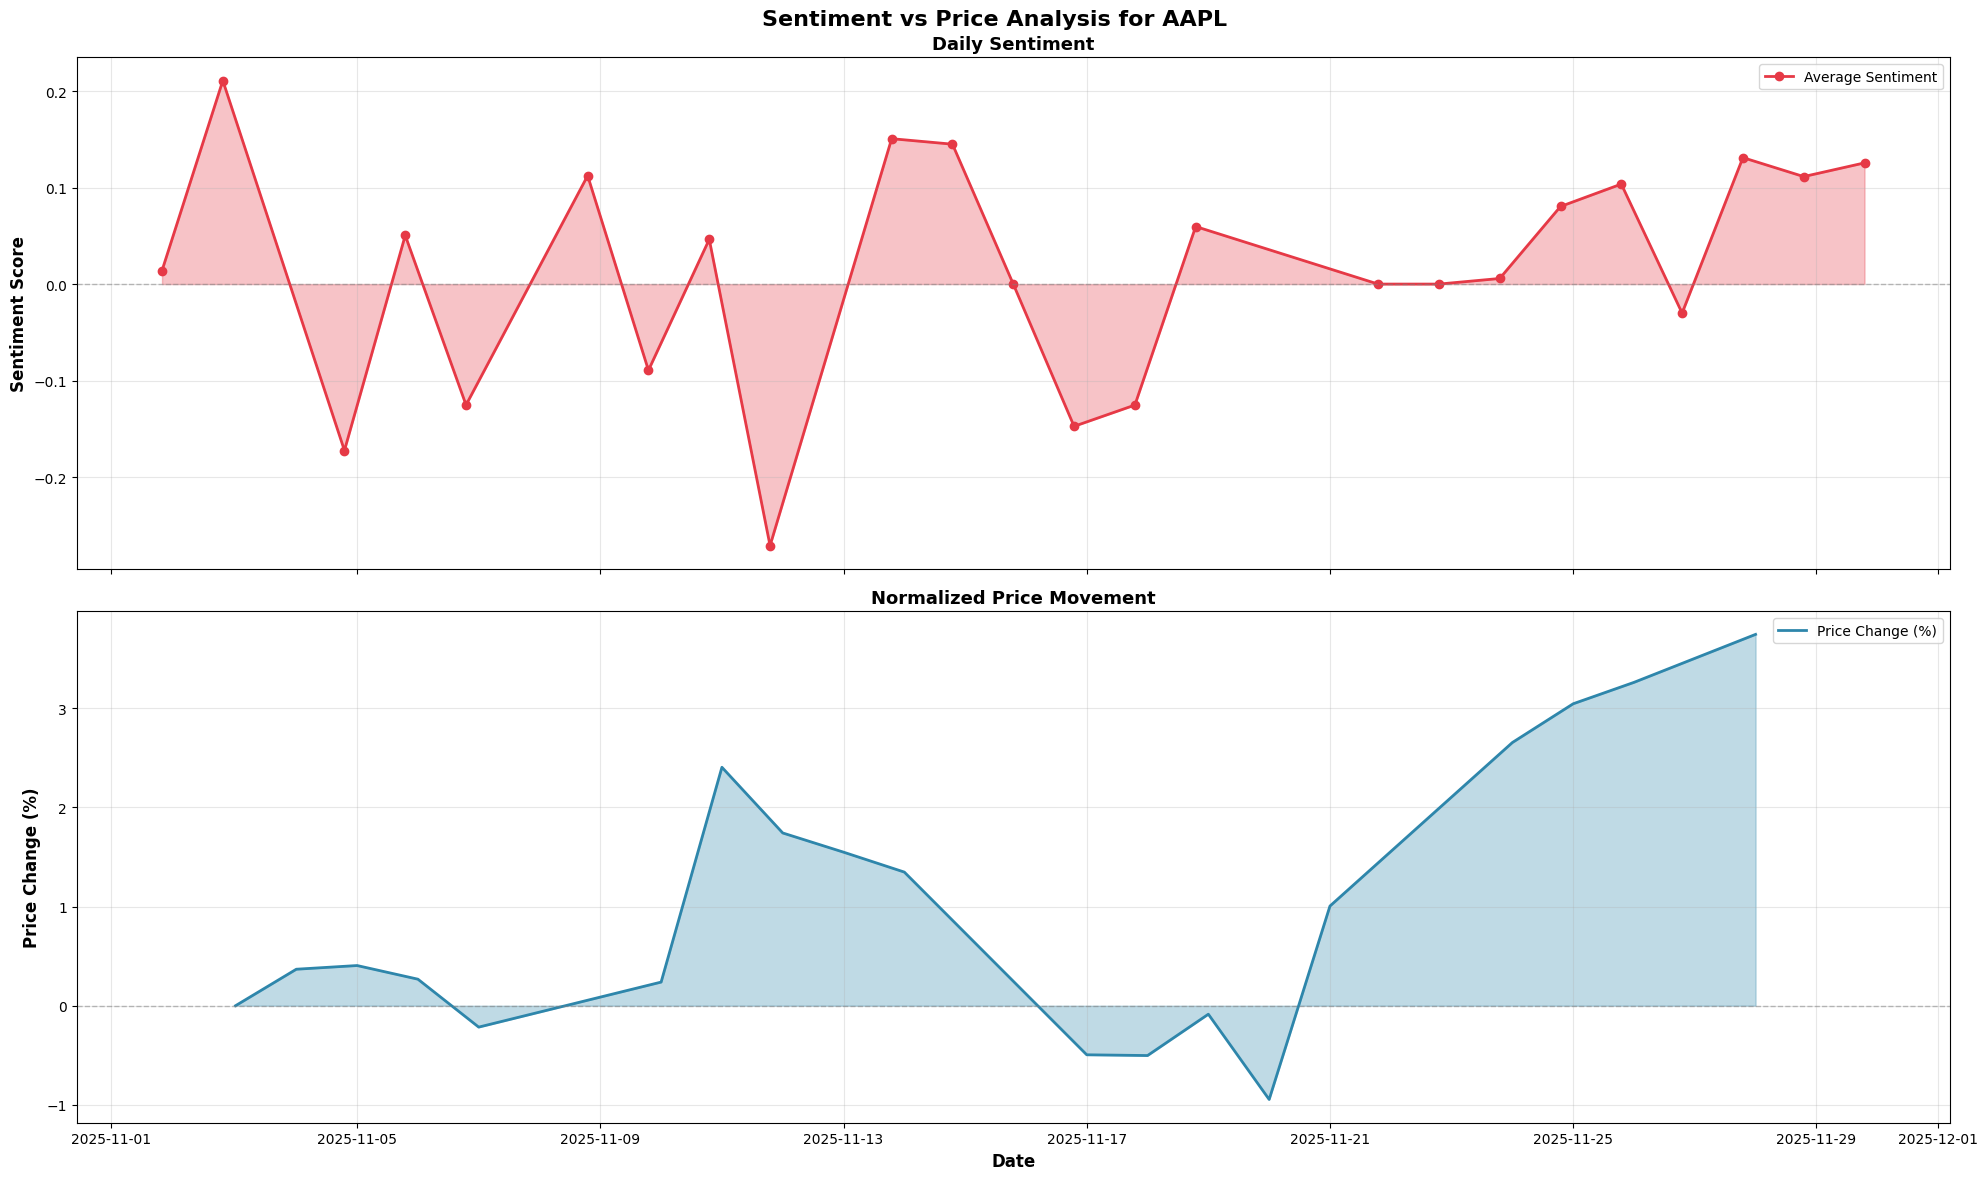

In [21]:
plot_sentiment_vs_price('AAPL')